# 01 · Preprocessing — Filbin 2018 Pediatric H3-K27M Mutant Glioma (malignant compartment)

Isolate malignant cells, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony), embed, remove detached islands, and split the manifold into
its transcriptional compartments. Filbin et al. profiled diffuse midline glioma (DIPG,
SmartSeq2) whose malignant cells occupy a developmental hierarchy — a cycling
**OPC-like** progenitor compartment differentiating toward **OC-like** and **AC-like**
states. Whether the gastrulation / somitogenesis / neural-crest developmental axis under
test is confined to one lobe (Kürten 2021) or spans the whole manifold (Bischoff / Sun /
Lee / Zhou 2020) is **derived in 02 from the signature geography**, not assumed here, so
all compartments are carried forward. Every tunable choice is *derived from this dataset*,
not inherited from the Puram anchor. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # 'Filbin2018_Brain-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
raw  = name[:-2] if name.endswith('-1') else name       # raw folder = dataset minus the -1 run suffix
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw)                       # raw input (no -1)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads (-1)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw input: Data_' + raw)

dataset: Filbin2018_Brain-1 | category: Brain | raw input: Data_Filbin2018_Brain


### Load malignant compartment
The loader auto-detects TPM (`Exp_data_TPM.mtx`) — expression passes through and is
`log1p`-transformed; `celltype` defaults to the publication's cell-type calls. Filbin's
`Cells.csv` annotates malignant vs. Oligodendrocyte / Macrophage; we take the
**Malignant** cells (per protocol) and coerce the published per-cell scores (cell-cycle
G1/S & G2/M, and the OPC-/OC-/AC-like hierarchy scores) to numeric for later use.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| cell types:', adata.obs.celltype.value_counts().to_dict())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
for c in ['g1s_score','g2m_score','opc_like','oc_like','ac_like','opc_variable','mp_top_score','complexity']:
    if c in adata.obs: adata.obs[c] = pd.to_numeric(adata.obs[c], errors='coerce')
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TPM)' % adata.X.max())
print('cell_cycle_phase:', adata.obs['cell_cycle_phase'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Filbin2018_Brain
Done.
full atlas: (2587, 23686) | cell types: {'Malignant': 2259, 'Oligodendrocyte': 232, 'Macrophage': 96}
malignant: (2259, 23686) | samples: 6
expression: X max 12.36 (log1p of TPM)
cell_cycle_phase: {'Not cycling': 1883, 'G1/S': 230, 'Intermediate': 77, 'G2/M': 69}


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts are read off *this* dataset (not the anchor's fixed ≥100). We
find the largest **multiplicative** cliff in the sorted counts and cut at its geometric
mean — the natural separatrix between well-sampled tumours and thin ones. Here the counts
are relatively smooth (largest ratio ≈1.7×), so the cut removes only the single thinnest
sample; this is reported transparently rather than forced to a round number.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells | dropped: {[s for s in n.index if s not in keep]}')

sorted per-sample counts: {'MUV05': np.int64(667), 'BCH869': np.int64(489), 'BCH836': np.int64(438), 'MUV10': np.int64(283), 'BCH1126': np.int64(241), 'MUV01': np.int64(141)}
largest multiplicative gap: 241 -> 141 (ratio 1.71)
derived threshold (geometric mean across the gap) = 184
kept 5/6 samples -> 2118 cells | dropped: ['MUV01']


### Overdispersion, PCA (scree-derived n_pcs), Harmony integration, embedding
`n_pcs` is derived from the **scree plot**, not inherited: the variance-ratio elbow is
sharp at PC5 with a structured shoulder to ~PC20 before flattening onto a noise floor, so
**n_pcs = 20** (the SmartSeq2 / ~2k-cell scale matches the Puram/Kürten precedents and
avoids the Chen-2020 under-powering at n_pcs=6). `theta` is selected by a per-neighbourhood
**iLISI** sweep (effective # samples mixed into each cell's neighbourhood): it rises from 1
(un-integrated) and plateaus by theta 5–10, so the strongest integration at the plateau
(**theta = 10**) is chosen — DIPG malignant cells carry strong patient-specific CNVs. UMAP
`spread = 1.3` follows the reference embeddings.

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3583 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3583
PCA variance ratio, PC1-24: [0.051, 0.0243, 0.0168, 0.0146, 0.0131, 0.0051, 0.0045, 0.0035, 0.0033, 0.0029, 0.0026, 0.0024, 0.0022, 0.002, 0.002, 0.0019, 0.0017, 0.0016, 0.0016, 0.0015, 0.0015, 0.0015, 0.0014, 0.0014]


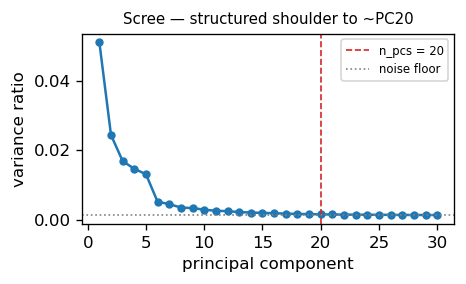

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio, PC1-24:', np.round(vr[:24], 4).tolist())

# scree figure (derivation shown, not asserted)
fig, ax = plt.subplots(figsize=(4,2.5))
ax.plot(np.arange(1,31), vr[:30], 'o-', ms=4, color='tab:blue')
ax.axvline(20, color='tab:red', ls='--', lw=1, label='n_pcs = 20')
ax.axhline(vr[22], color='grey', ls=':', lw=1, label='noise floor')
ax.set_xlabel('principal component'); ax.set_ylabel('variance ratio')
ax.set_title('Scree — structured shoulder to ~PC20', size=9); ax.legend(fontsize=7)
fig.tight_layout()

In [6]:
from sklearn.neighbors import NearestNeighbors
N_PCS = 20
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return np.median(out)
nsamp = adata.obs['sample'].nunique()
il_pre = _ilisi(adata.obsm['X_pca'][:,:N_PCS], adata.obs['sample'].values)
sweep = {}
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = round(_ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], adata.obs['sample'].values), 2)
print(f'iLISI median (of {nsamp} samples) | pre-Harmony {il_pre:.2f} | theta sweep {sweep}')
theta = 10
print(f'selected theta = {theta} (per-neighbourhood mixing plateaus 5->10; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

iLISI median (of 5 samples) | pre-Harmony 1.00 | theta sweep {1: np.float64(2.09), 2: np.float64(2.8), 5: np.float64(3.49), 10: np.float64(3.66)}
selected theta = 10 (per-neighbourhood mixing plateaus 5->10; strongest integration without collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and keep only
the largest connected component — stripping physically detached specks while preserving the
continuous trajectory termini. On this manifold no cells detach (already one component).

In [7]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached islands removed:', int((lab!=main).sum()), 'cells in', ncomp-1, 'components')
adata = adata[lab==main].copy()
print('retained:', adata.shape[0], 'cells in one connected component')

detached islands removed: 0 cells in 0 components
retained: 2118 cells in one connected component


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. We label them *by biology*:
the compartment with the **lower cycling fraction** is the **Embryonic** candidate, the rest
**Cycling/Metabolic** (`cell_cycle_phase` is the publication's phase call). Whether the
trajectory is scoped to one lobe or spans all is decided in 02 from the signature geography,
not assumed here.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 1155, '1': 630, '2': 333}
cycling fraction per lobe: {'0': 0.07, '1': 0.46, '2': 0.02}
compartments: {'Cycling/Metabolic': 1785, 'Embryonic': 333}


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding, so all trajectory panels are
shown after a single **rigid rotation** to the house horizontal layout (distance-preserving
— *not* a re-embedding, which would fabricate folds in an anisotropic strip). The angle is
the manifold's **axis of maximal variance**; the sign puts the **developmental-origin pole
(Gast/pSom-high) on the left** so pseudotime will run left→right once the curve is rooted at
that origin in 02. (For this dataset the cycling compartment sits toward the *neural-crest*
end rather than the origin — cyc_score rises with the module axis — so the sign is taken from
the developmental modules directly, not from a proliferation proxy; the modules are scored
here purely to fix the orientation sign and re-scored formally in 02–03.) Derived once here,
stored as `X_umap_lin`, and re-used unchanged by 02–04 so every deliverable UMAP shares one
orientation (binding).

In [9]:
# score the three developmental modules (union control pool) to fix the orientation sign
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_data,'features','biomart','*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name='_'+lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
origin = (adata.obs['_Gast'] + adata.obs['_pSom'] - adata.obs['_Crest']).values   # high at developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],
               [np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin - origin.min() + 1e-9                          # developmental-origin pole -> left
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
adata.obs.drop(columns=['_Gast','_pSom','_Crest'], inplace=True)   # keep obs tidy; modules re-scored in 02
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'developmental-origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.83
house orientation: rigid rotation +179.6deg (distances preserved), developmental-origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made
on the **regenerated embedding itself** plus a per-neighbourhood metric (iLISI across the
theta sweep above), never a single scalar. Both criteria hold: iLISI rises to ~3.7 of 5
samples at theta=10 and every lobe contains multiple patients; the manifold is one connected
component. **Gate 1 = GO.** The deliverable `samples.pdf` follows.

In [10]:
nsamp = adata.obs['sample'].nunique()
il_post = _ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], adata.obs['sample'].values)
print(f'iLISI median post-Harmony(theta=10): {il_post:.2f} of {nsamp} samples (pre-Harmony {il_pre:.2f})')
print('samples per lobe:')
print(pd.crosstab(adata.obs['lobe'], adata.obs['sample']).to_string())
print(f'\n{nsamp} samples share one continuous manifold (one connected component); every lobe is multi-patient.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median post-Harmony(theta=10): 3.66 of 5 samples (pre-Harmony 1.00)
samples per lobe:
sample  BCH1126  BCH836  BCH869  MUV05  MUV10
lobe                                         
0           155     235     235    366    164
1            62     154     113    218     83
2            24      49     141     83     36

5 samples share one continuous manifold (one connected component); every lobe is multi-patient.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data

In [11]:
# coerce any remaining object columns for clean h5ad serialization
for col in adata.obs.columns:
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum()>=0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2118, 21106)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip on the house orientation (`X_umap_lin`),
`size=30`. Colour = sample; intermixing across the strip is the Gate-1 batch-integration
evidence, shown on the same orientation as every 02–04 UMAP (binding).

saved samples.pdf | cells: 2118


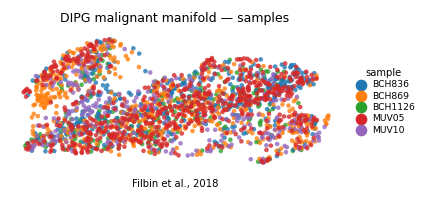

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('DIPG malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])